       Feature  LinearRegression  LogisticRegression
0    Feature_1         46.325998            0.365327
1    Feature_2         -0.034162            0.192593
2    Feature_3         58.330507           -0.092085
3    Feature_4          0.428824           -0.018583
4    Feature_5         -0.429282            0.318828
5    Feature_6         -0.371167            0.051909
6    Feature_7         34.541479            0.110655
7    Feature_8         83.323917            0.263697
8    Feature_9         93.923940           -0.047535
9   Feature_10         27.815506           -0.694468
10  Feature_11         -0.122906            0.238142
11  Feature_12         -0.043569           -0.175397
12  Feature_13         -0.057731            0.140888
13  Feature_14          4.891230            0.445823
14  Feature_15          0.245706            0.202846
15  Feature_16          0.085308           -0.171273
16  Feature_17          4.833278            0.255383
17  Feature_18         35.585044           -0.

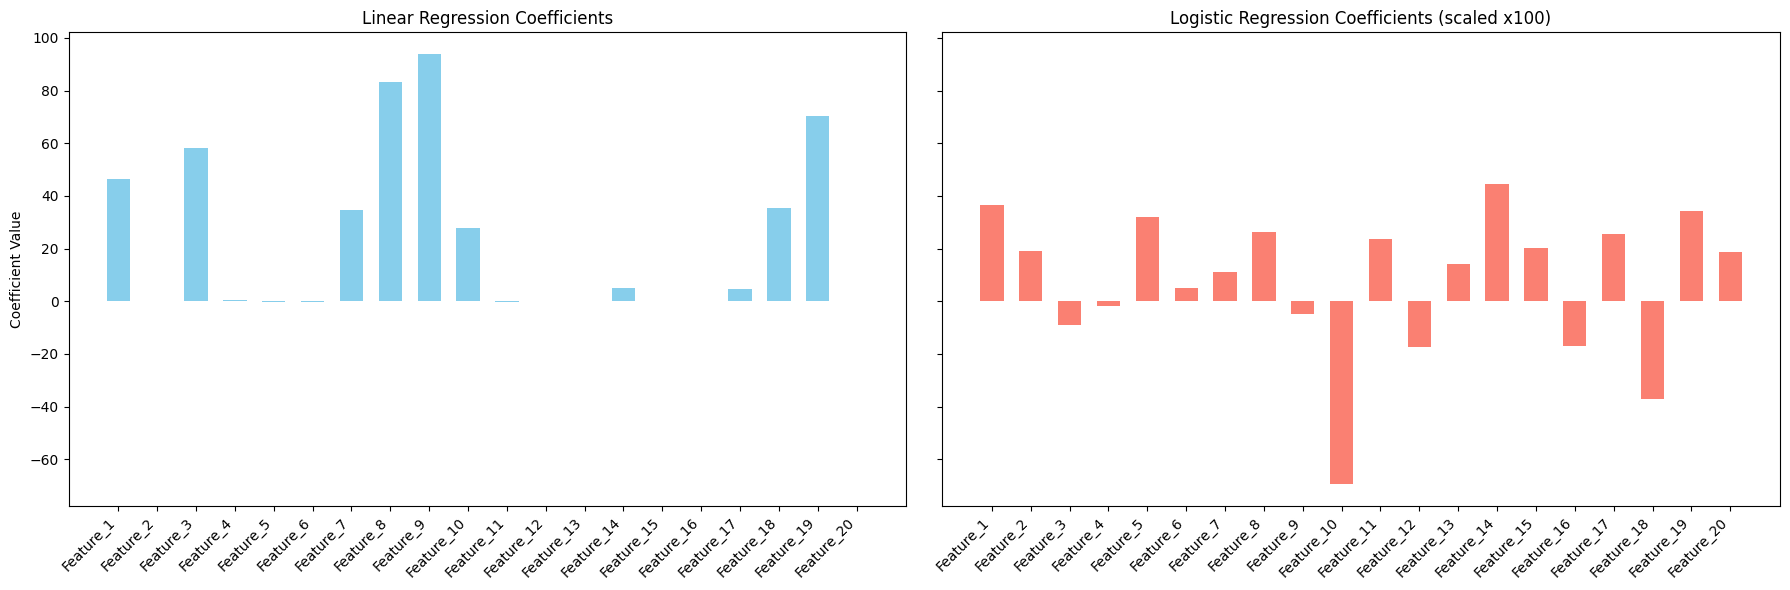

In [5]:
from sklearn.datasets import make_regression, make_classification
from sklearn.linear_model import LinearRegression, LogisticRegression
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# -------------------------
# 1) Synthetic Regression Dataset
# -------------------------
X_reg, y_reg = make_regression(
    n_samples=2000,
    n_features=20,
    n_informative=10,
    noise=10.0,
    random_state=42
)

feature_names = [f"Feature_{i+1}" for i in range(X_reg.shape[1])]

# Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_reg, y_reg)
lr_coefs = lr_model.coef_

# -------------------------
# 2) Synthetic Classification Dataset
# -------------------------
X_clf, y_clf = make_classification(
    n_samples=2000,
    n_features=20,
    n_informative=10,
    n_redundant=5,
    n_repeated=0,
    n_classes=2,
    random_state=42
)

# Logistic Regression
log_model = LogisticRegression(solver='liblinear')
log_model.fit(X_clf, y_clf)
log_coefs = log_model.coef_[0]

# -------------------------
# Combine feature importances (keep original order)
# -------------------------
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "LinearRegression": lr_coefs,
    "LogisticRegression": log_coefs
})

print(importance_df)

# -------------------------
# Side-by-side plots with all features in original order
# -------------------------
fig, axes = plt.subplots(1, 2, figsize=(18,6), sharey=True)

indices = np.arange(len(feature_names))
bar_width = 0.6

# Scaling factor for logistic coefficients
scale_factor = 100

# Linear Regression plot
axes[0].bar(indices, importance_df['LinearRegression'], bar_width, color='skyblue')
axes[0].set_xticks(indices)
axes[0].set_xticklabels(importance_df['Feature'], rotation=45, ha='right')
axes[0].set_title("Linear Regression Coefficients")
axes[0].set_ylabel("Coefficient Value")

# Logistic Regression plot (scaled)
axes[1].bar(indices, importance_df['LogisticRegression']*scale_factor, bar_width, color='salmon')
axes[1].set_xticks(indices)
axes[1].set_xticklabels(importance_df['Feature'], rotation=45, ha='right')
axes[1].set_title(f"Logistic Regression Coefficients (scaled x{scale_factor})")

plt.tight_layout()
plt.show()
